# Convolutions

In this lab, we'll look in detail at convolutions and how they can be used to process images.

### Reading and opening images

We'll use the `skimage` library to read and process images. It's a library dedicated to image processing, which is part of the `scikit-learn` family.

In [4]:
## Tensorflow GPU disabled by default. Comment the following lines to enable GPU if you have a working CUDA installation.
import tensorflow as tf

try:
    # Disable all GPUs
    tf.config.set_visible_devices([], 'GPU')

    visible_devices = tf.config.get_visible_devices()
    for device in visible_devices:
        assert device.device_type != 'GPU'
    print("GPUs disabled, using CPU.")

except:
    # Invalid device or cannot modify virtual devices once initialized.
    pass

GPUs disabled, using CPU.


In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
%pip install scikit-image
import skimage
print("scikit-image:", skimage.__version__)

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.1/11.9 MB 249.8 kB/s eta 0:00:48
   - -------------------------------------- 0.3/11.9 MB 791.9 kB/s eta 0:00:15
   -- ------------------------------------- 0.7/11.9 MB 1.7 MB/s eta 0:00:07
   ---- ----------------------------------- 1.3/11.9 MB 2.7 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/11.9 MB 3.5 MB/s eta 0:00:03
   ------- -------------------------------- 2.3/11.


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


sample image shape:  (400, 600, 3)


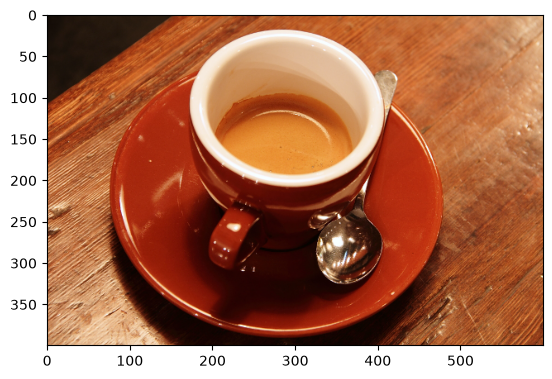

In [7]:
sample_image = skimage.data.coffee()

size = sample_image.shape
print("sample image shape: ", sample_image.shape)

plt.imshow(sample_image.astype('uint8'));

### A simple convolution filter

Before we start working on training any models, let's look at applying a convolution filter to an image. We'll use the `Conv2D` layer from Keras to do this.

In [8]:
from tensorflow.keras.layers import Conv2D

In [9]:
conv = Conv2D(filters=3, kernel_size=(5, 5), padding="same")

Remember: in Keras, `None` is used as a marker for tensor dimensions with dynamic size. In this case `batch_size`, `width` and `height` are all dynamic: they can depend on the input. This is a neat feature of convolutional neural networks: the same model can be used to process images of any size, because all we have to do is slide the convolutional filter across the image as much as necessary.

In [10]:
sample_image.shape

(400, 600, 3)

In [11]:
img_in = np.expand_dims(sample_image, 0).astype(float)
img_in.shape

(1, 400, 600, 3)

In [12]:
img_out = conv(img_in) # Apply the convolutional filter

The output is a tensorflow Eager Tensor - a special data structure that is used to represent the result of operations in TensorFlow. It is not a numpy array, but it can be converted to one using the `.numpy()` method:

In [13]:
np_img_out = img_out[0].numpy()
print(type(np_img_out))
print(np_img_out.shape)

<class 'numpy.ndarray'>
(400, 600, 3)


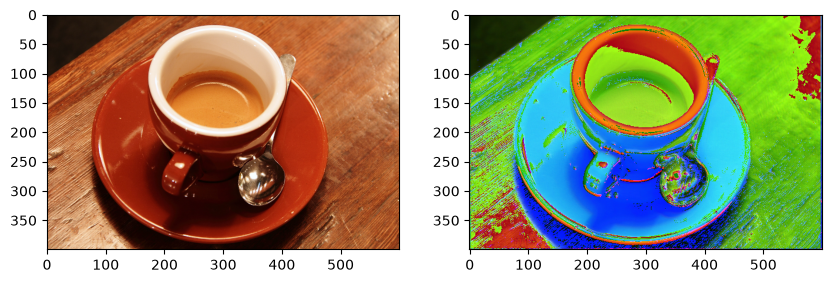

In [14]:
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 5))
ax0.imshow(sample_image.astype('uint8'))
ax1.imshow(np_img_out.astype('uint8'));

As we can see, our convolutional filter was initialized randomly, so our output doesn't contain any specific meaning. Each pixel is a random combination of the pixels in the input image, in a 5x5 window.

Let's instead take a look at a convolutional feature with a clear purpose. We can build a kernel ourselves, by defining a function which will be passed to `Conv2D` Layer.
We'll create an array with 1/25 for filters, with each channel seperated. Before you move to the next cell, can you guess what this filter will do?

In [15]:
def my_kernel(shape=(5, 5, 3, 3), dtype=None):
    array = np.zeros(shape=shape, dtype="float32")
    array[:, :, 0, 0] = 1 / 25
    array[:, :, 1, 1] = 1 / 25
    array[:, :, 2, 2] = 1 / 25
    return array

Now we can use this function to initialize a `Conv2D` layer:

In [16]:
conv = Conv2D(filters=3, kernel_size=(5, 5), padding="same", kernel_initializer=my_kernel)

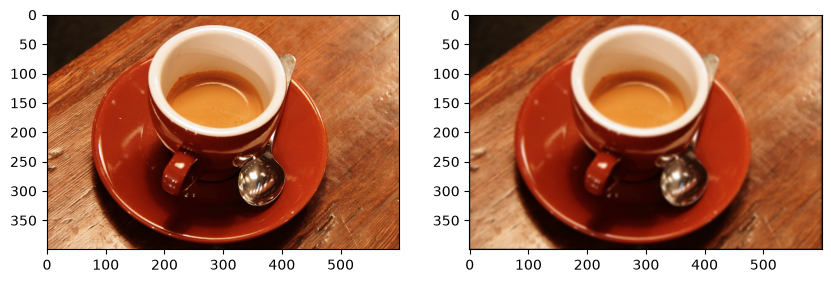

In [17]:
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 5))
ax0.imshow(img_in[0].astype('uint8'))

img_out = conv(img_in)
np_img_out = img_out[0].numpy()
ax1.imshow(np_img_out.astype('uint8'));

Hopefully you can tell what this filter does!

**Exercise**
- There are a number of settings when we define our Conv2D layer. Try changing the following parameters to get a sense of how they impact the result:
- kernel_size: try different sizes
- padding: try 'valid' instead of 'same' (hint: this may change the size of the output)

Kernel 3x3, padding=same: (400, 600, 3) -> (400, 600, 3)
Kernel 5x5, padding=same: (400, 600, 3) -> (400, 600, 3)
Kernel 9x9, padding=same: (400, 600, 3) -> (400, 600, 3)
Kernel 3x3, padding=valid: (400, 600, 3) -> (398, 598, 3)
Kernel 5x5, padding=valid: (400, 600, 3) -> (396, 596, 3)
Kernel 9x9, padding=valid: (400, 600, 3) -> (392, 592, 3)


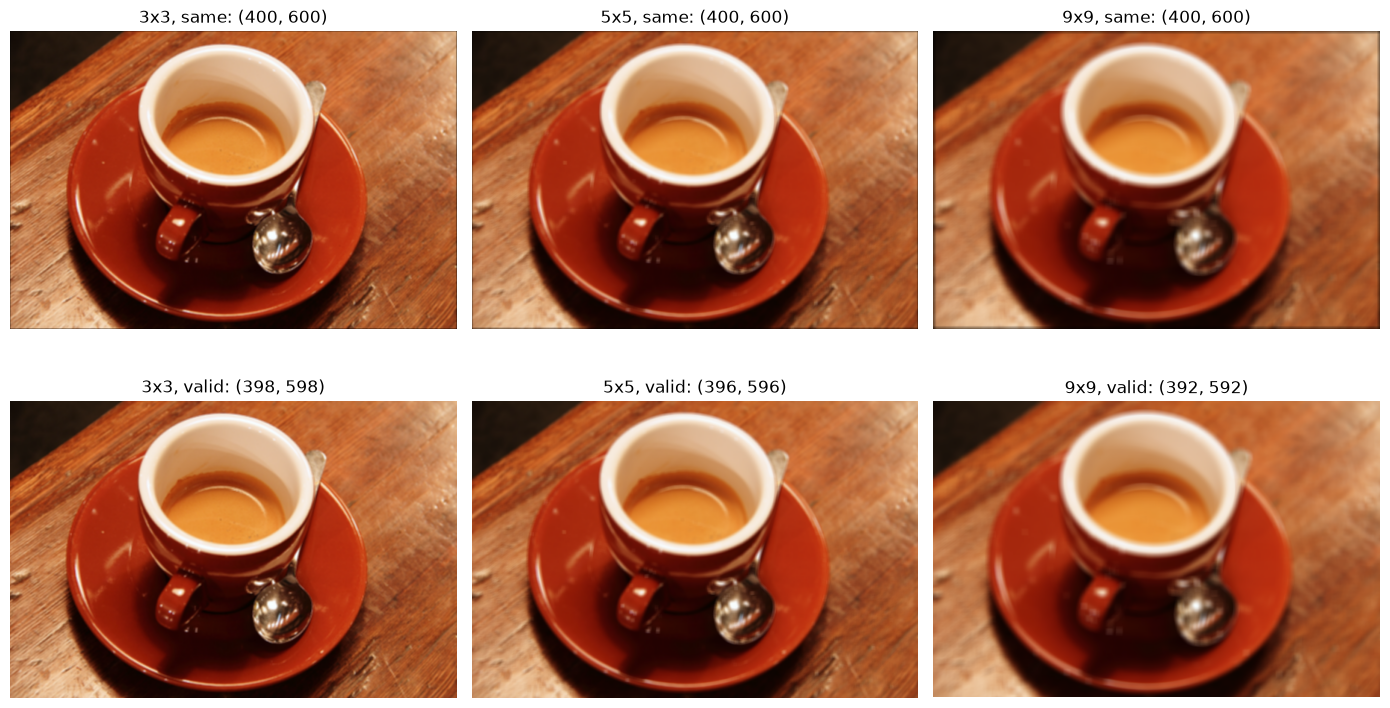

In [18]:
def averaging_kernel(shape, dtype=None):
    k_h, k_w, in_channels, out_channels = shape
    weights = np.zeros(shape, dtype=np.float32)
    for channel in range(min(in_channels, out_channels)):
        weights[:, :, channel, channel] = 1.0 / (k_h * k_w)
    return weights

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, padding_mode in enumerate(['same', 'valid']):
    for col, kernel_width in enumerate([3, 5, 9]):
        trial_conv = Conv2D(filters=3, kernel_size=(kernel_width, kernel_width),
                            padding=padding_mode,
                            kernel_initializer=averaging_kernel,
                            use_bias=False)
        output = trial_conv(img_in).numpy()[0]
        print(f'Kernel {kernel_width}x{kernel_width}, padding={padding_mode}: '
              f'{img_in.shape[1:]} -> {output.shape}')
        axes[row, col].imshow(np.clip(output, 0, 255).astype(np.uint8))
        axes[row, col].set_title(f'{kernel_width}x{kernel_width}, {padding_mode}: {output.shape[:2]}')
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

# Answer: Larger kernels create stronger blurring. With stride 1, 'same'
# keeps the original image dimensions; 'valid' removes k-1 pixels from
# each spatial dimension for a k x k kernel (e.g., 400x600 -> 396x596 for k=5).

### Working on edge detection on Grayscale image

Using a grayscale image, let's build an "edge detector" using a convolutional filter. Some filters pre-date the deep learning era and are still used today. For example, the Sobel filter is used to detect edges in images. These easy-to-compute filters were used in the early days of computer vision and are still useful now.

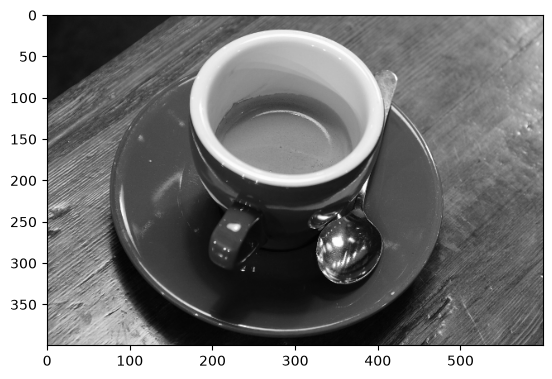

In [20]:
# convert image to greyscale
grey_sample_image = sample_image.mean(axis=2)

# add the channel dimension even if it's only one channel so
# to be consistent with Keras expectations.
grey_sample_image = grey_sample_image[:, :, np.newaxis]

# matplotlib does not like the extra dim for the color channel
# when plotting gray-level images. Let's use squeeze:
plt.imshow(np.squeeze(grey_sample_image.astype(np.uint8)),
           cmap=plt.cm.gray);

**Exercise**
- Build an edge detector using `Conv2D` on greyscale image by defining the kernel inside `my_kernel`.
- You may experiment with several kernels to find a way to detect edges. The following article contains specific examples of kernels that you can use:
- https://en.wikipedia.org/wiki/Kernel_(image_processing)
- Try different kernels and see the impact on the output.

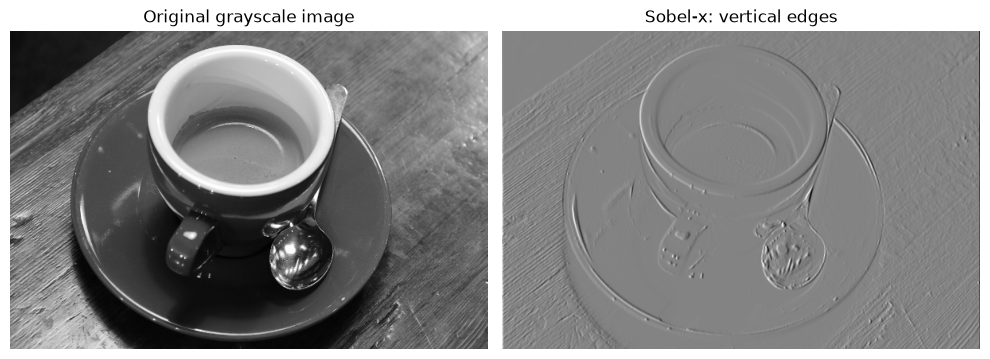

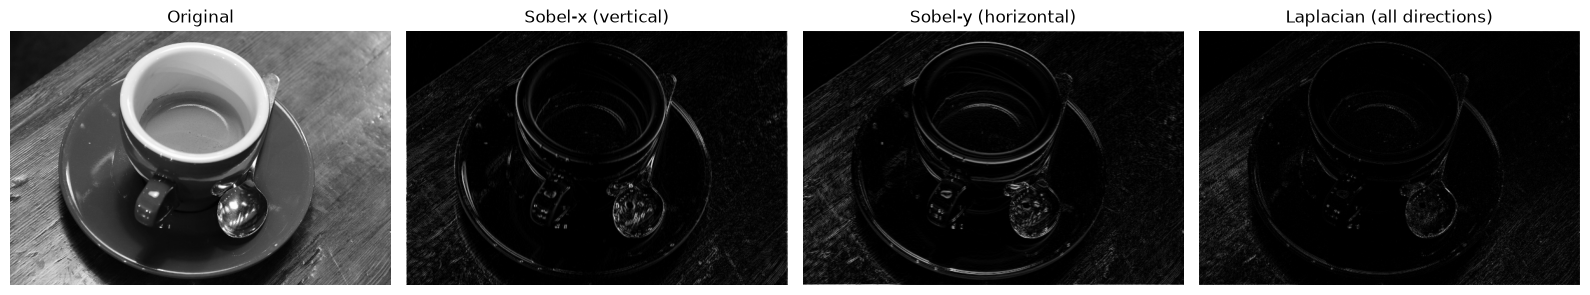

In [21]:
# Exercise: define a Sobel-x kernel to detect vertical edges.
def my_kernel(shape=(3, 3, 1, 1), dtype=None):
    array = np.array([[-1, 0, 1],
                      [-2, 0, 2],
                      [-1, 0, 1]], dtype=np.float32)
    return array.reshape(shape)

conv = Conv2D(filters=1, kernel_size=(3, 3), padding="same",
              kernel_initializer=my_kernel, use_bias=False)
img_in = np.expand_dims(grey_sample_image, 0)  # Batch of one grayscale image
img_out = conv(img_in)
np_img_out = img_out[0].numpy()

fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 5))
ax0.imshow(np.squeeze(grey_sample_image), cmap=plt.cm.gray)
ax0.set_title('Original grayscale image')
ax1.imshow(np.squeeze(np_img_out), cmap=plt.cm.gray)
ax1.set_title('Sobel-x: vertical edges')
for ax in (ax0, ax1):
    ax.axis('off')
plt.tight_layout()
plt.show()

# Try other kernels from the completed sample (Sobel-y and Laplacian).
edge_kernels = {
    'Sobel-x (vertical)': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    'Sobel-y (horizontal)': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    'Laplacian (all directions)': np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(np.squeeze(grey_sample_image), cmap='gray')
axes[0].set_title('Original')
for ax, (label, kernel_2d) in zip(axes[1:], edge_kernels.items()):
    def custom_kernel(shape, dtype=None, kernel=kernel_2d):
        return kernel.reshape(shape)
    layer = Conv2D(filters=1, kernel_size=(3, 3), padding='same',
                   kernel_initializer=custom_kernel, use_bias=False)
    response = layer(img_in).numpy()[0, :, :, 0]
    ax.imshow(np.abs(response), cmap='gray')
    ax.set_title(label)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# Answer: Sobel-x detects vertical boundaries; Sobel-y detects horizontal
# boundaries; Laplacian responds to brightness changes in both directions.
# Show floating-point edge responses (or absolute values) instead of casting
# negative responses directly to uint8.

### Pooling and strides with convolutions

**Exercise**
- Use `MaxPool2D` to apply a 2x2 max pool with strides 2 to the image. What is the impact on the shape of the image?
- Use `AvgPool2D` to apply an average pooling.
- Is it possible to compute a max pooling and an average pooling with well chosen kernels?

Original input shape: (1, 400, 600, 1)
Max pooled shape: (200, 300)
Average pooled shape: (200, 300)


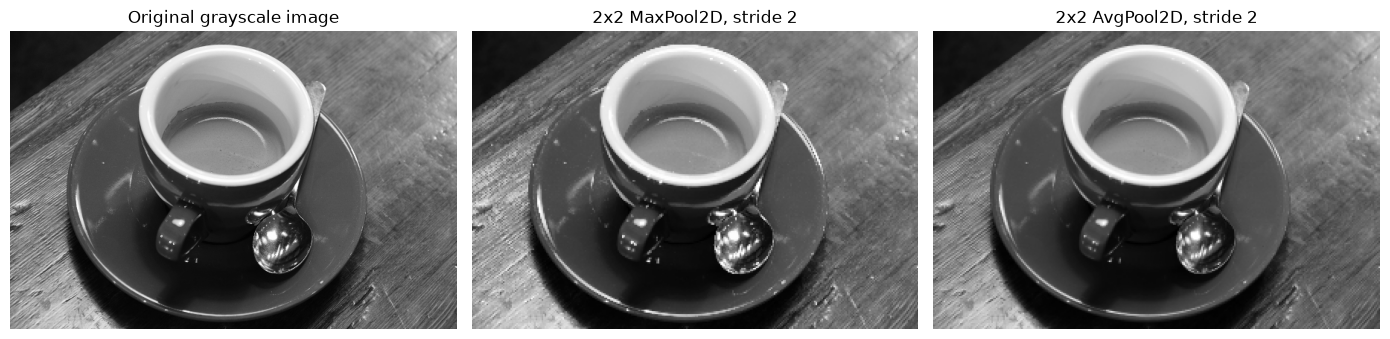

Max absolute difference between AvgPool2D and average convolution: 0.0
Average pooling reproduced by convolution: True


In [22]:
from tensorflow.keras.layers import MaxPool2D, AvgPool2D

# Exercise: use 2x2 pooling windows with strides of 2.
# img_in is the (1, height, width, 1) grayscale batch from above.
pool_in = img_in
max_pool = MaxPool2D(pool_size=(2, 2), strides=(2, 2), padding='valid')
avg_pool = AvgPool2D(pool_size=(2, 2), strides=(2, 2), padding='valid')
max_out = max_pool(pool_in).numpy()[0, :, :, 0]
avg_out = avg_pool(pool_in).numpy()[0, :, :, 0]
print('Original input shape:', pool_in.shape)
print('Max pooled shape:', max_out.shape)
print('Average pooled shape:', avg_out.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(np.squeeze(grey_sample_image), cmap='gray')
axes[0].set_title('Original grayscale image')
axes[1].imshow(max_out, cmap='gray')
axes[1].set_title('2x2 MaxPool2D, stride 2')
axes[2].imshow(avg_out, cmap='gray')
axes[2].set_title('2x2 AvgPool2D, stride 2')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# Average pooling can be matched by a convolution with a uniform 2x2 kernel.
def mean_pool_kernel(shape, dtype=None):
    return np.full(shape, 0.25, dtype=np.float32)
mean_conv = Conv2D(filters=1, kernel_size=(2, 2), strides=(2, 2),
                   padding='valid', kernel_initializer=mean_pool_kernel,
                   use_bias=False)
conv_avg = mean_conv(pool_in).numpy()[0, :, :, 0]
print('Max absolute difference between AvgPool2D and average convolution:',
      np.max(np.abs(avg_out - conv_avg)))
print('Average pooling reproduced by convolution:', np.allclose(avg_out, conv_avg, atol=1e-4))

# Answer: 400x600 -> 200x300 after 2x2 pooling with stride 2.
# Average pooling is equivalent to a fixed linear convolution with equal
# weights and stride 2; max pooling is nonlinear, so it cannot generally
# be reproduced with a single fixed convolution kernel.

## Loading a JPEG file as a numpy array

Let's use [scikit-image](http://scikit-image.rg) to load the content of a JPEG file into a numpy array:

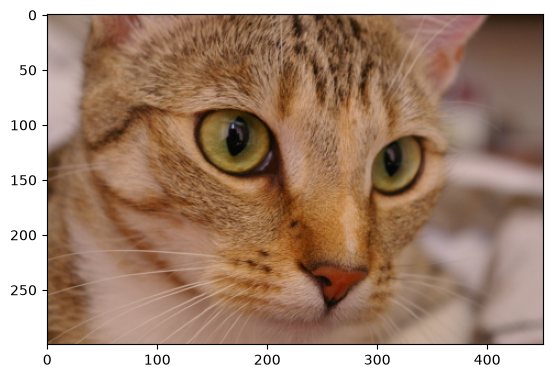

In [23]:
from skimage.io import imread

image = skimage.data.cat()
plt.imshow(image);

## Resizing images, handling data types and dynamic ranges

While convolutions can handle inputs of any size, it is often useful to resize images to a fixed size. This is particularly important for training deep learning models:

- for **image classification**, most networks expect a specific **fixed input size**;

- for **object detection** and instance segmentation, networks have more flexibility but the image should have **approximately the same size as the training set images**.

Furthermore **large images can be much slower to process** than smaller images (the number of pixels varies quadratically with the height and width).

In [24]:
from skimage.transform import resize

lowres_image = resize(image, (50, 50), mode='reflect', anti_aliasing=True)
lowres_image.shape

(50, 50, 3)

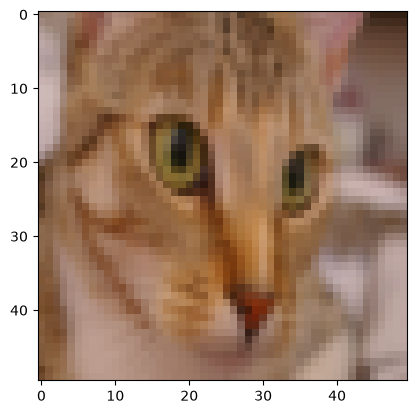

In [25]:
plt.imshow(lowres_image, interpolation='nearest');

The values of the pixels of the low resolution image are computed from by combining the values of the pixels in the high resolution image. The result is therefore represented as floating points.

## Using a pretrained model

Objectives:

- Load a pre-trained ResNet50 pre-trained model using Keras Zoo
- Use the model to classify an image
- Use the model to classify an image from the webcam

Let's start with loading ResNet50, a well-established method for image classification. The ResNet50 "application" takes two key parameters here: firstly, `include_top` indicates whether we want to include the last layer of the network (the classification layer) or not. Secondly, `weights` indicates whether we want to load the weights of a model that has been pre-trained on ImageNet or not.

In [28]:
from tensorflow.keras.applications.resnet50 import ResNet50

model = ResNet50(include_top=True, weights='imagenet')
model.compile(optimizer='sgd', loss='categorical_crossentropy')

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


In [29]:
print(model.summary())

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)

None


### Classification of an image

**Exercise**
- Reshape the `cat` image to the shape `(224, 224, 3)` using `resize` from `skimage.transform`
- Use `preprocess_input` from `tensorflow.keras.applications.imagenet_utils` to preprocess the image
- Use `predict` to classify the image

Documentation for each method:
- [resize](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize)
- [preprocess_input](https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet/preprocess_input)
- [predict](https://www.tensorflow.org/api_docs/python/tf/keras/Model#predict)

Model input shape: (1, 224, 224, 3)
Prediction shape: (1, 1000)
Top 5 predictions for cat image:
Egyptian_cat: 95.70%
tiger_cat: 1.83%
tabby: 1.75%
shower_cap: 0.46%
plastic_bag: 0.11%


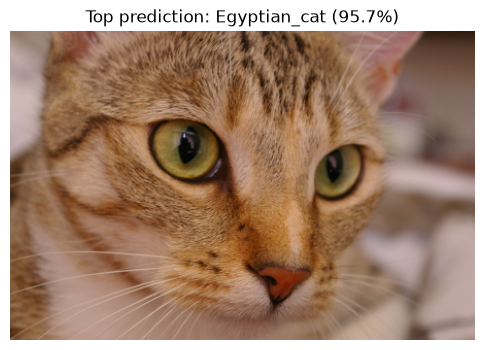

In [31]:
from tensorflow.keras.applications.resnet50 import preprocess_input, decode_predictions

# Resize the cat image to the size required by ResNet50.
input_image = resize(image, (224, 224, 3), mode='reflect', anti_aliasing=True)

# Scale to [0, 255] (skimage.resize returns a floating point image in [0, 1]).
input_image = (input_image * 255).astype(np.float32)

# Prepare for model: one image in a batch.
input_image = np.expand_dims(input_image, axis=0)

# Preprocess the image using the ResNet50 preprocessing routine.
processed_image = preprocess_input(input_image.copy())
predictions = model.predict(processed_image, verbose=0)
print('Model input shape:', processed_image.shape)
print('Prediction shape:', predictions.shape)
print('Top 5 predictions for cat image:')
cat_top5 = decode_predictions(predictions, top=5)[0]
for _, label, probability in cat_top5:
    print(f'{label}: {probability:.2%}')

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(f'Top prediction: {cat_top5[0][1]} ({cat_top5[0][2]:.1%})')
plt.axis('off')
plt.show()

# Answer: the network accepts a (1, 224, 224, 3) batch and outputs 1,000
# ImageNet probabilities. Actual classes and probabilities print above.

##  Taking snapshots from the webcam

For this section, we will take an image from your laptop webcam and classify it. If you feel uncomfortable doing this section, you can skip it and use a photo of your choice from the web instead.

In [32]:
# The webcam section is optional. OpenCV is imported only if requested.
def camera_grab(camera_id=0, fallback_filename=None):
    try:
        import cv2
    except ImportError:
        print('OpenCV is unavailable; using a fallback image.')
        return imread(fallback_filename) if fallback_filename else skimage.data.astronaut()

    camera = cv2.VideoCapture(camera_id)
    captured_image = None
    try:
        # Take several frames so the webcam can adjust exposure.
        for _ in range(10):
            snapshot_ok, frame = camera.read()
            if snapshot_ok:
                captured_image = frame
    finally:
        camera.release()
    if captured_image is None:
        print('WARNING: could not access camera; using fallback image.')
        return imread(fallback_filename) if fallback_filename else skimage.data.astronaut()
    return cv2.cvtColor(captured_image, cv2.COLOR_BGR2RGB)

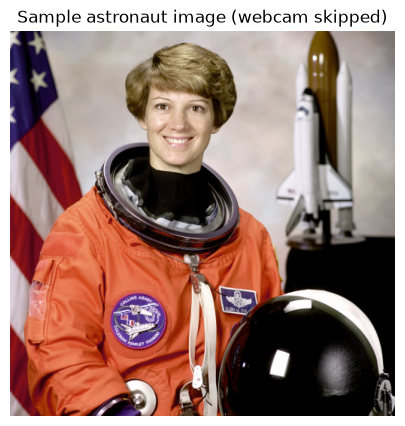

dtype: uint8, shape: (512, 512, 3), range: (np.uint8(0), np.uint8(255))


In [33]:
# Set this to True if you want to classify a picture from your webcam.
# The instructor also allows a different image; here we use a built-in sample
# when the webcam is not requested.
USE_WEBCAM = False
if USE_WEBCAM:
    image = camera_grab(camera_id=0, fallback_filename=None)
    image_source = 'Webcam (or fallback if unavailable)'
else:
    image = skimage.data.astronaut()
    image_source = 'Sample astronaut image (webcam skipped)'
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(image_source)
plt.axis('off')
plt.show()
print('dtype: {}, shape: {}, range: {}'.format(
    image.dtype, image.shape, (image.min(), image.max())))

### Exercise

Apply the same preprocessing as before and classify the image. What are your results?

Image source: Sample astronaut image (webcam skipped)
Input batch shape: (1, 224, 224, 3)
Top 5 predictions for second image:
bobsled: 28.10%
go-kart: 15.43%
ski: 8.10%
space_shuttle: 5.51%
shield: 4.45%


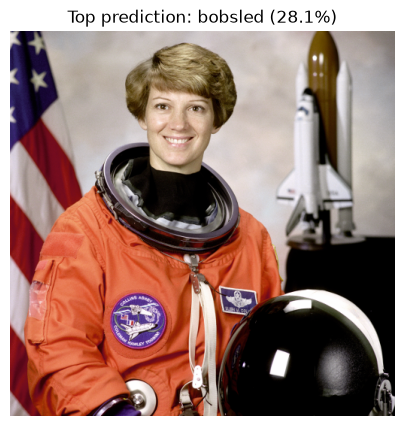

In [34]:
# Exercise: apply the same preprocessing and classify the webcam/second image.

# Resize the image to (224, 224, 3).
input_image = resize(image, (224, 224, 3), mode='reflect', anti_aliasing=True)

# Scale to [0, 255] range (resize returns [0, 1]).
input_image = (input_image * 255).astype(np.float32)

# Add a batch dimension, preprocess using ResNet50, and predict.
input_image = np.expand_dims(input_image, axis=0)
processed_image = preprocess_input(input_image.copy())
predictions = model.predict(processed_image, verbose=0)
print('Image source:', image_source)
print('Input batch shape:', processed_image.shape)
print('Top 5 predictions for second image:')
second_top5 = decode_predictions(predictions, top=5)[0]
for _, label, probability in second_top5:
    print(f'{label}: {probability:.2%}')

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(f'Top prediction: {second_top5[0][1]} ({second_top5[0][2]:.1%})')
plt.axis('off')
plt.show()

# Answer: same (1, 224, 224, 3) preprocessing as before. The printed
# probabilities and predicted labels are the results for this second image;
# they can differ from the cat image because the content is different.